# Simple Linear Regression

## Objective

To build Simple Linear Regression models for TV, Radio and Newspaper advertising expenditure to understand their individual relationships with product Sales and compare their predictive performance.

## Business Question 

Can product Sales be predicted using TV, Radio and Newspaper advertising expenditure individually?

## Simple Linear Regression Models

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_and_split, eval_regression

df_train, df_test = load_and_split(
    path=PROJECT_ROOT / "Dataset" / "Advertising.csv"
)

df = df_train.copy()

In [10]:
features = ['tv', 'radio', 'newspaper']
target = 'sales'

In [11]:
import statsmodels.api as sm
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

models = {}
results = []

# Mean-prediction baseline on training data
dummy = DummyRegressor(strategy='mean')
dummy.fit(df[['tv']], df[target])
dummy_cv_r2 = cross_val_score(dummy, df[['tv']], df[target], cv=5, scoring='r2').mean()
dummy_cv_rmse = -cross_val_score(dummy, df[['tv']], df[target], cv=5, scoring='neg_root_mean_squared_error').mean()
results.append({
    'Model': 'Baseline (Mean)',
    'Intercept': dummy.constant_[0][0],
    'Coefficient': 0.0,
    'p-value': np.nan,
    'Train R2': 0.0,
    'CV R2 (5-fold)': dummy_cv_r2,
    'CV RMSE (5-fold)': dummy_cv_rmse,
    'Train RMSE': eval_regression(df[target], dummy.predict(df[['tv']]))['RMSE']
})

for feature in features:
    X_train = df[[feature]]
    y_train = df[target]

    model = LinearRegression()
    model.fit(X_train, y_train)
    models[feature] = model

    y_train_pred = model.predict(X_train)
    metrics = eval_regression(y_train, y_train_pred)

    cv_r2 = cross_val_score(model, X_train, y_train, cv=5, scoring='r2').mean()
    cv_rmse = -cross_val_score(model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error').mean()

    ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
    label = 'TV' if feature == 'tv' else feature.title()

    results.append({
        'Model': label,
        'Intercept': model.intercept_,
        'Coefficient': model.coef_[0],
        'p-value': ols.pvalues[feature],
        'Train R2': metrics['R2'],
        'CV R2 (5-fold)': cv_r2,
        'CV RMSE (5-fold)': cv_rmse,
        'Train RMSE': metrics['RMSE']
    })

results_df = pd.DataFrame(results)
results_df.round(4)

,Model,Intercept,Coefficient,p-value,Train R2,CV R2 (5-fold),CV RMSE (5-fold),Train RMSE
0,Baseline (Mean),14.1000,0.0000,NaN,0.0000,-0.2007,5.2022,5.0928
1,TV,7.1196,0.0465,0.0000,0.5912,0.5380,3.2692,3.2563
2,Radio,9.4241,0.2044,0.0000,0.3509,0.1713,4.1926,4.1031
3,Newspaper,12.3105,0.0598,0.0025,0.0566,-0.1643,5.1065,4.9466


### Interpretation of Simple Linear Regression Results
1. TV: R² = 0.591, meaning TV advertising expenditure explains approximately 59.1% of the variation in Sales. It performs the best among the three individual models.

2. Radio: R² = 0.351, indicating that Radio advertising explains approximately 35.1% of the variation in Sales.

3. Newspaper: R² = 0.057, meaning Newspaper advertising explains only 5.7% of the variation in Sales. It has the weakest predictive performance.

Among the three individual models, TV advertising provides the best fit and predictive performance, while Newspaper performs the weakest.

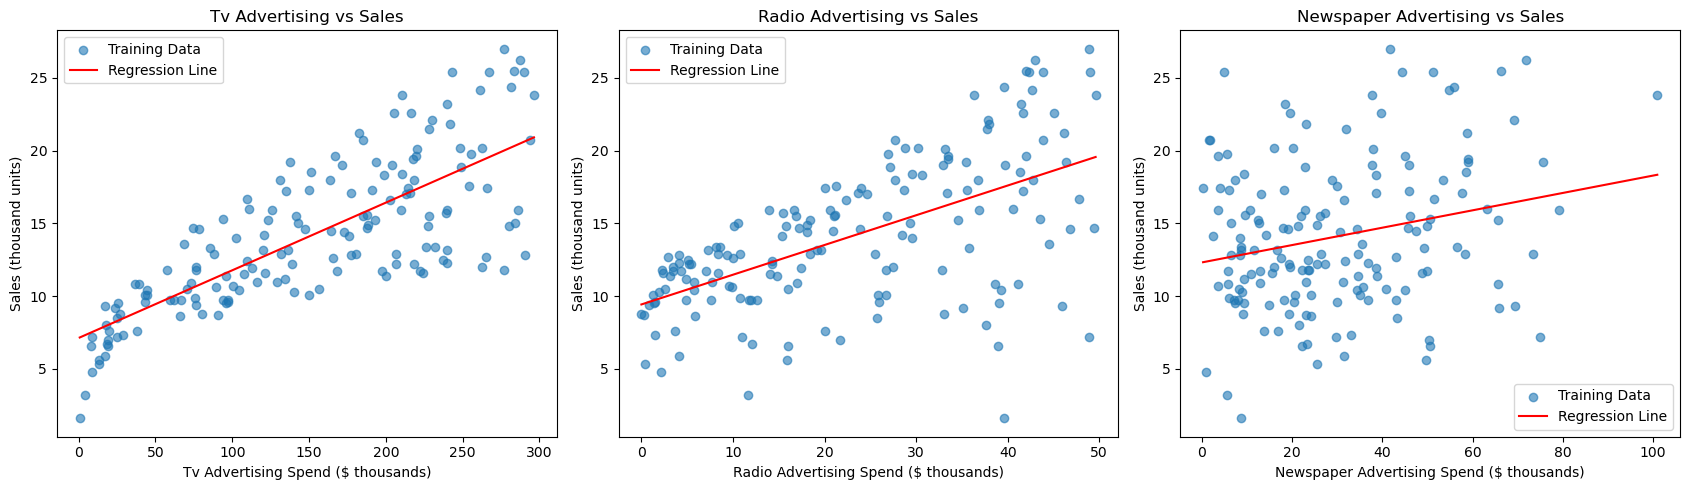

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, feature in zip(axes, features):

    X_plot = pd.DataFrame({
        feature: np.sort(df[feature])
    })

    y_line = models[feature].predict(X_plot)

    # Training observations
    ax.scatter(
        df[feature],
        df[target],
        alpha=0.6,
        label="Training Data"
    )

    # Regression line
    ax.plot(
        X_plot[feature],
        y_line,
        color="red",
        label="Regression Line"
    )

    ax.set_title(f"{feature.title()} Advertising vs Sales")
    ax.set_xlabel(f"{feature.title()} Advertising Spend ($ thousands)")
    ax.set_ylabel("Sales (thousand units)")
    ax.legend()

plt.tight_layout()
plt.show()

##  Residual Analysis

## Objective
 Understand how far the model's predictions are from the actual Sales values and identify any patterns in the prediction errors.

Residual = Actual Sales - Predicted Sales

- Positive residual: The model underpredicted Sales.
- Negative residual: The model overpredicted Sales.
- Zero residual: The prediction was exactly correct.

In [13]:
residuals = {}

for feature in features:

    X_train = df[[feature]]
    y_train = df[target]

    y_pred = models[feature].predict(X_train)

    residuals[feature] = y_train - y_pred

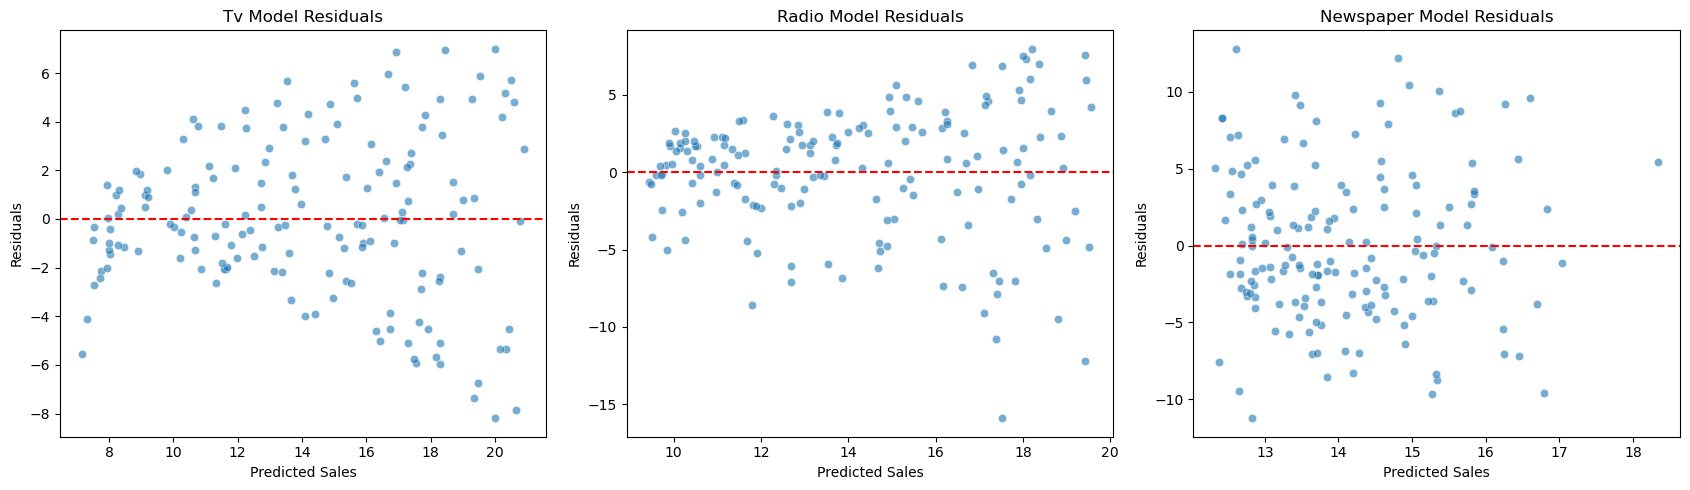

In [14]:
# plot residuals vs predicted values

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, feature in zip(axes, features):

    y_pred = models[feature].predict(df[[feature]])

    sns.scatterplot(
        x=y_pred,
        y=residuals[feature],
        ax=ax,
        alpha=0.6
    )

    ax.axhline(
        y=0,
        color='red',
        linestyle='--'
    )

    ax.set_title(f'{feature.title()} Model Residuals')
    ax.set_xlabel('Predicted Sales')
    ax.set_ylabel('Residuals')

plt.tight_layout()
plt.show()

### Residual Plot Interpretation

- **TV Model Residuals:** The residuals are not evenly scattered around zero. At lower predicted sales, the errors stay fairly tight, but as predicted sales increase, the vertical spread widens noticeably into a fan shape, ranging from roughly -8 to +7. This points to non-constant variance and suggests that a straight line misses diminishing returns at higher TV budgets.
- **Radio Model Residuals:** Most markets sit slightly above zero, but there are several sharp negative residuals dropping down to around -15. Those happen when a market spends heavily on radio while spending almost nothing on TV, so the model overpredicts sales because radio alone cannot drive high volume without TV support.
- **Newspaper Model Residuals:** Predicted sales stay bunched in a narrow band around 13 to 16, while the actual residuals spread widely from roughly -11 to +13. The model essentially predicts near the average for almost every market, confirming that newspaper spend carries very little standalone signal.

### Key Findings

- **Baseline benchmark:** Always predicting the training mean of 14.1000 yields a 5-fold CV RMSE of 5.2022, which sets the bar any useful model must beat.
- **TV is the strongest standalone driver:** TV explains 59.12% of training variance and achieves a 5-fold CV R² of 0.5380 with a CV RMSE of 3.2692, cutting prediction error by about 37% relative to the mean baseline.
- **Radio provides moderate standalone signal:** Radio reaches a training R² of 0.3509, but its 5-fold CV R² drops to 0.1713 with a CV RMSE of 4.1926, showing substantial fold-to-fold variance when TV spend is not accounted for.
- **Newspaper fails out-of-sample:** Even though Newspaper has a statistically significant slope on the training set with a p-value of 0.0025, it explains only 5.66% of training variance and produces a negative 5-fold CV R² of -0.1643 with a CV RMSE of 5.1065, performing no better than the mean baseline.
- **Next step:** Single-channel linear models still leave over 3.27 units of RMSE unexplained and show curved patterns in the residuals, so Notebook 4 will test multiple regression, the TV-by-radio interaction, and non-linear TV transformations.

## Conclusion
TV advertising expenditure provides the strongest individual predictive relationship with Sales, followed by Radio. Newspaper advertising alone provides limited predictive power.

These results suggest that using multiple advertising channels together may improve sales prediction. We will investigate this further using Multiple Linear Regression in the next notebook.